#### Task 1 - Linear Regression

In [81]:
# Importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_squared_error, root_mean_squared_error

In [82]:
# Load data
df = pd.read_csv("electronic_store_sample_data.csv")

In [83]:
# Select a numerical target variable
target = "Total Price"
features = ["Unit Price", "Quantity", "Age", "Rating"]   # numerical features

X = df[features]
y = df[target]

In [84]:
# Split the data into training and testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [85]:
# Train a Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 5.41,578.97, 0.18, -1. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Unit Price','Quantity','Age','Rating']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3133
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [86]:
# Make predictions on test data
y_pred = model.predict(X_test)

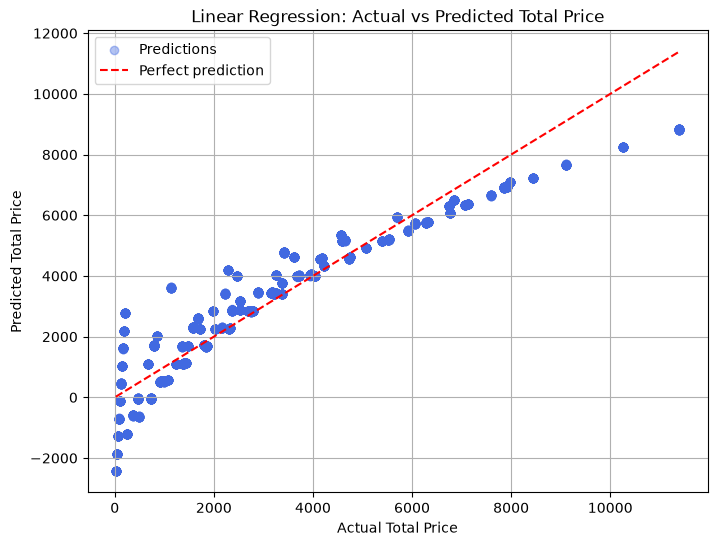

In [87]:
# Plot Actual vs Predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4, color="royalblue", label="Predictions")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual Total Price")
plt.ylabel("Predicted Total Price")
plt.title("Linear Regression: Actual vs Predicted Total Price")
plt.legend()
plt.grid(True)
plt.show()

#### Task 2 - Regression Evaluation Metrics

In [88]:
print("MAE      :", mean_absolute_error(y_test, y_pred))
print("MSE      :", mean_squared_error(y_test, y_pred))
print("RMSE     :", root_mean_squared_error(y_test, y_pred))

MAE      : 671.3678597188359
MSE      : 790747.9961398604
RMSE     : 889.2401228801253


#### Task 3 - Logistic Regression

In [89]:
# Importing required packages
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [90]:
# Select a classification target variable
# Encoding it with label encoder
le = LabelEncoder()
df["Order Status"] = le.fit_transform(df["Order Status"])

# Separating the feature with target
features = ["Age", "Rating", "Unit Price", "Quantity", "Total Price",
            "Gender", "Loyalty Member", "Product Type", "Shipping Type"]

X = pd.get_dummies(df[features], drop_first=True)   # converts text columns to numbers
y = df["Order Status"]

In [91]:
# Split data into training and testing sets (80/20)
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features (helps Logistic Regression converge)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [92]:
# Train a Logistic Regression model and making predections
model = LogisticRegression()
model.fit(x_train, y_train)

reg_y_pred = model.predict(x_test)

In [93]:
 # Evaluation
# print("Accuracy:", accuracy_score(y_test, reg_y_pred))
# print("\nConfusion Matrix:\n", confusion_matrix(y_test, reg_y_pred))
# print("\nClassification Report:\n", classification_report(y_test, reg_y_pred))

#### Task 4 - Navie Bayes Classiifier

In [94]:
from sklearn.naive_bayes import GaussianNB

# Train a Logistic Regression model and making predections
model = GaussianNB()
model.fit(x_train, y_train)

navie_bayes_y_pred = model.predict(x_test)

In [95]:
 # Evaluation
# print("Accuracy:", accuracy_score(y_test, navie_bayes_y_pred))
# print("\nConfusion Matrix:\n", confusion_matrix(y_test, navie_bayes_y_pred))
# print("\nClassification Report:\n", classification_report(y_test, navie_bayes_y_pred))

#### Task 5 - K-Nearest Neighbour

In [96]:
# Features: numerical + one-hot encoded categorical
num_cols = ["Age", "Rating", "Unit Price", "Quantity", "Total Price"]
cat_cols = ["Gender", "Loyalty Member", "Product Type", "Shipping Type"]

In [97]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop="first", sparse_output=False)
ohe_df = pd.DataFrame(ohe.fit_transform(df[cat_cols]),
                      columns=ohe.get_feature_names_out(cat_cols),
                      index=df.index)
X = pd.concat([df[num_cols], ohe_df], axis=1)

In [98]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [99]:
# Scale features (important for KNN)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [100]:
# Train a KNN classifier with several different k values

from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 61, 71, 81, 91, 95, 100]
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"k = {k:>2}  ->  Accuracy = {acc:.4f}")

k =  1  ->  Accuracy = 0.5448
k =  3  ->  Accuracy = 0.5785
k =  5  ->  Accuracy = 0.5930
k =  7  ->  Accuracy = 0.6102
k =  9  ->  Accuracy = 0.6125
k = 11  ->  Accuracy = 0.6234
k = 15  ->  Accuracy = 0.6363
k = 21  ->  Accuracy = 0.6531
k = 31  ->  Accuracy = 0.6650
k = 41  ->  Accuracy = 0.6680
k = 51  ->  Accuracy = 0.6690
k = 61  ->  Accuracy = 0.6693
k = 71  ->  Accuracy = 0.6700
k = 81  ->  Accuracy = 0.6693
k = 91  ->  Accuracy = 0.6696
k = 95  ->  Accuracy = 0.6696
k = 100  ->  Accuracy = 0.6693


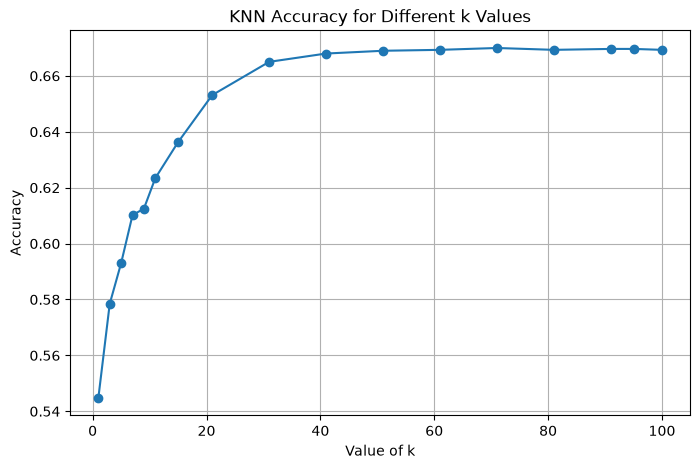

In [101]:
# Observe accuracy changes (plot)
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker="o")
plt.xlabel("Value of k")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different k Values")
plt.grid(True)
plt.show()

In [102]:
# Select the best-performing k
best_idx = accuracies.index(max(accuracies))
best_k = k_values[best_idx]
knn_y_pred = knn.predict(X_test)
print(f"\nBest k = {best_k} with accuracy = {accuracies[best_idx]:.4f}")


Best k = 71 with accuracy = 0.6700


#### Task 6 - Evaluation Metrics for Classification

In [103]:
print("<============Logistic Regression============>")
print("Accuracy:", accuracy_score(y_test, reg_y_pred))
print("Precision:", precision_score(y_test, reg_y_pred))
print("Recall:", recall_score(y_test, reg_y_pred))
print("F1-Score:", f1_score(y_test, reg_y_pred))
print("Classification Report:\n", classification_report(y_test, reg_y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, reg_y_pred))

print("\n<============Navie Bayes============>")
print("Accuracy:", accuracy_score(y_test, navie_bayes_y_pred))
print("Precision:", precision_score(y_test, navie_bayes_y_pred))
print("Recall:", recall_score(y_test, navie_bayes_y_pred))
print("F1-Score:", f1_score(y_test, navie_bayes_y_pred))
print("Classification Report:\n", classification_report(y_test, navie_bayes_y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, navie_bayes_y_pred))

print("\n<============K-nearest Neighbour============>")
print("Accuracy:", accuracy_score(y_test, knn_y_pred))
print("Precision:", precision_score(y_test, knn_y_pred))
print("Recall:", recall_score(y_test, knn_y_pred))
print("F1-Score:", f1_score(y_test, knn_y_pred))
print("Classification Report:\n", classification_report(y_test, knn_y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, knn_y_pred))

<============Logistic Regression============>
Accuracy: 0.6703006276841758
Precision: 0.6703006276841758
Recall: 1.0
F1-Score: 0.8026107594936709
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       998
           1       0.67      1.00      0.80      2029

    accuracy                           0.67      3027
   macro avg       0.34      0.50      0.40      3027
weighted avg       0.45      0.67      0.54      3027

Confusion Matrix:
 [[   0  998]
 [   0 2029]]

<============Navie Bayes============>
Accuracy: 0.6703006276841758
Precision: 0.6703006276841758
Recall: 1.0
F1-Score: 0.8026107594936709
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       998
           1       0.67      1.00      0.80      2029

    accuracy                           0.67      3027
   macro avg       0.34      0.50      0.40      3027
weighted avg       0.4

c:\Users\Lenovo\Desktop\GEN_AI\gen_ai_course\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Lenovo\Desktop\GEN_AI\gen_ai_course\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Lenovo\Desktop\GEN_AI\gen_ai_course\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capi

#### Task 7 - Overfitting & Underfitting

In [104]:
# Importing required packages
from sklearn.tree import DecisionTreeClassifier

In [105]:
# Train models with different complexity
models = {
    "Underfit (max_depth=1)":   DecisionTreeClassifier(max_depth=1, random_state=42),
    "Balanced (max_depth=5)":   DecisionTreeClassifier(max_depth=5, random_state=42),
    "Overfit (max_depth=None)": DecisionTreeClassifier(max_depth=None, random_state=42),
}

In [106]:
# Compare training vs testing accuracy
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    results.append([name, train_acc, test_acc])
    print(f"{name:<26} Train = {train_acc:.4f} | Test = {test_acc:.4f} | Depth = {model.get_depth()}")

results_df = pd.DataFrame(results, columns=["Model", "Train Accuracy", "Test Accuracy"])

Underfit (max_depth=1)     Train = 0.6705 | Test = 0.6703 | Depth = 1
Balanced (max_depth=5)     Train = 0.6734 | Test = 0.6683 | Depth = 5
Overfit (max_depth=None)   Train = 0.9756 | Test = 0.5349 | Depth = 39


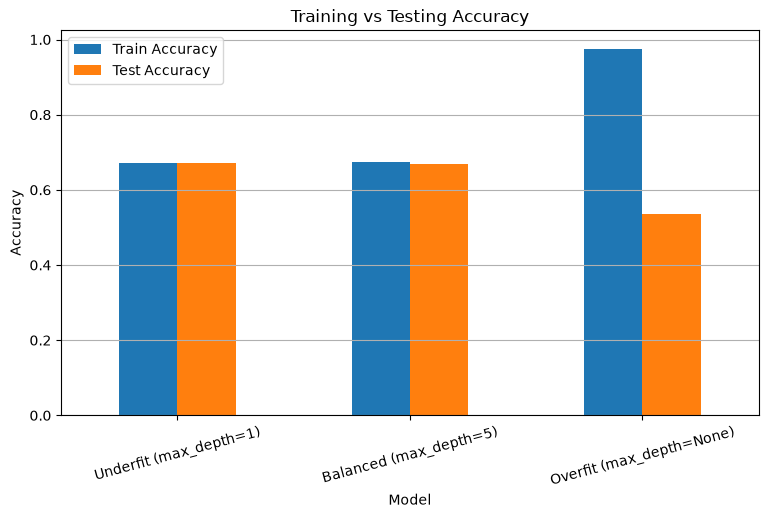

In [107]:
# Plot comparison
results_df.set_index("Model").plot(kind="bar", figsize=(9, 5))
plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()

#### Task 8 - Bias & Variance (Conceptual)

1. What is bias in ML models?

Bias is the error that comes from a model being too simple or making wrong assumptions about the data. A high-bias model misses real patterns, so it makes consistently inaccurate predictions on both training and test data. For example, fitting a straight line to data that follows a curve.

2. What is variance?

Variance is how much a model’s predictions change when it’s trained on different samples of data. A high-variance model is too sensitive to the training data, picking up noise as if it were a real pattern. It performs very well on training data but poorly on new data.

3. How do bias and variance relate to underfitting and overfitting?

-> Underfitting = high bias. The model is too simple to learn the patterns.<br>
-> Overfitting = high variance. The model is too complex and memorizes the training data, noise included.<br>
-> This is the bias-variance tradeoff: making a model more complex lowers bias but raises variance, and making it simpler does the opposite. The goal is a balance that gives the lowest error on new data.

4. How can we reduce overfitting?

-> Get more training data, so the model can’t memorize it as easily.<br>
-> Simplify the model, for example by limiting tree depth (max_depth) or using fewer features.<br>
-> Cross-validation: evaluate on multiple train/validation splits to catch overfitting early.<br>
-> Feature selection: remove irrelevant or noisy features.<br>
-> Ensemble methods such as Random Forest, which average many models to reduce variance.<br>